In [1]:
# Imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from scipy.interpolate import PchipInterpolator
from scipy.interpolate import make_interp_spline
from scipy.optimize import curve_fit

In [ ]:
from calibration_settings_patch import DATASET, SETTINGS, OUTPUT_DIR, rows
print(f"Dataset: {DATASET}")
discharge_directory = OUTPUT_DIR

compiled_file_name = Path.joinpath(discharge_directory, "final_cleaned_compiled.csv")
points_of_interest_file_name = Path.joinpath(discharge_directory, "points_of_interest.json")
RC_values_file_name = Path.joinpath(discharge_directory, "RC_values.csv")
ocv_soc_dict_file_name = Path.joinpath(discharge_directory, "ocv_soc_dict.csv")

output_file_name = Path.joinpath(discharge_directory, "final_cleaned_compiled (with SoC).csv")

Dataset: LiFePO4


In [3]:
points_of_interest = json.load(open(points_of_interest_file_name, 'r'))

In [4]:
compiled_df = pd.read_csv(compiled_file_name)

In [5]:
average_current = ((compiled_df['Calibrated Current 1'] + compiled_df['Calibrated Current 2']) / 2 + 
                   ((compiled_df['Calibrated Current 1'] + compiled_df['Calibrated Current 2']) / 2).shift(1)) / 2
average_current[average_current < 0] = 0
average_current = average_current.fillna(0)

delta_time = compiled_df['Translated Time'].diff() / 1000  # Convert ms to seconds
delta_time = delta_time.fillna(0)

compiled_df['Charge Change'] = average_current * delta_time

sensor_draw_estimate = 0.081

total_charge = compiled_df['Charge Change'].sum()
total_Ah = (total_charge / 3600) - sensor_draw_estimate

print(f"Total Charge: {total_charge:.4f} Coulombs")
print(f"Total Ah: {total_Ah:.4f} Ah")

Total Charge: 133535.7810 Coulombs
Total Ah: 37.0123 Ah


In [ ]:
compiled_df['SoC'] = 100.0
# SoC from discharge curve
total_charge = total_Ah * 3600  # Convert Ah to Coulombs
accumulated_charge = compiled_df['Charge Change'].cumsum().shift(1, fill_value=0)
compiled_df["SoC"] = (total_charge - accumulated_charge) / total_charge * 100

In [7]:
compiled_df.head(10)

,Translated Time,Translated Time (minutes),ADS Reading 1 (Smoothed and Offset),Calibrated Current 1,ADS Reading 2 (Smoothed and Offset),Calibrated Current 2,ADS Reading 3 (Smoothed),Calibrated Voltage,File,Charge Change,SoC
0,0.000,0.000000,32755.0,-0.030601,32730.0,-0.089471,55913.0,52.419237,0,0.0,100.0
1,0.942,0.000016,32746.0,-0.051791,32722.5,-0.107137,55913.5,52.420175,0,0.0,100.0
2,1.880,0.000031,32737.0,-0.072985,32722.0,-0.108315,55914.0,52.419237,0,0.0,100.0
3,2.819,0.000047,32755.0,-0.030601,32722.0,-0.108315,55914.0,52.420175,0,0.0,100.0
4,3.757,0.000063,32737.0,-0.072985,32722.0,-0.108315,55914.0,52.420175,0,0.0,100.0
5,4.699,0.000078,32731.0,-0.087116,32722.0,-0.108315,55914.0,52.421112,0,0.0,100.0
6,5.637,0.000094,32737.0,-0.072985,32722.0,-0.108315,55914.0,52.420175,0,0.0,100.0
7,6.576,0.000110,32745.0,-0.054146,32718.0,-0.117738,55914.0,52.420175,0,0.0,100.0
8,7.514,0.000125,32737.0,-0.072985,32714.0,-0.127162,55914.0,52.421112,0,0.0,100.0
9,8.452,0.000141,32735.0,-0.077695,32714.0,-0.127162,55914.0,52.420175,0,0.0,100.0


In [8]:
before_close = points_of_interest['before_close']
before_open = points_of_interest['before_open']
before_close['SoC'] = []
before_open['SoC'] = []
for index in before_close['index']:
    before_close['SoC'].append(compiled_df.at[index, 'SoC'])

for index in before_open['index']:
    before_open['SoC'].append(compiled_df.at[index, 'SoC'])
    
print(f"Before Close: {json.dumps(before_close)}")
print(f"Before Open: {json.dumps(before_open)}")
print(len(before_close['SoC']), len(before_close['voltage']))
print(len(before_open['SoC']), len(before_open['voltage']))

Before Close: {"index": [1483134, 2661550, 3847382, 5131081, 6553096, 7798618, 9047841], "time": [23.956198208833328, 43.51606308758333, 62.65763838408333, 83.45462005700001, 106.46658475708337, 126.64025422725003, 146.72836396641668], "voltage": [52.82702795147631, 52.63496877088578, 52.325396859693285, 52.22101401693752, 52.187961950103, 51.90299041428243, 51.23709275349051], "SoC": [83.94676500619315, 70.48791875916746, 59.29410959886293, 46.85740460254018, 34.83046742252191, 22.82274741499905, 10.957110741685339]}
Before Open: {"index": [775588, 2083835, 3233723, 4484330, 5755372, 7165339, 8419225], "time": [12.4705109035, 34.18474398275, 52.70260938199999, 73.04924402541668, 93.53072202125, 116.42497142525004, 136.6567733346667], "voltage": [50.26931548638133, 50.57320606088349, 50.50136902723736, 50.39884246280613, 50.21225367818724, 49.9552388189517, 49.374097138933394], "SoC": [84.12226642041911, 70.65469741891226, 59.45572706772051, 47.016401763583566, 34.98910281003078, 22.98

In [ ]:
trimmed_df = compiled_df
# Retaill original data frame

C:\Users\Kor\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


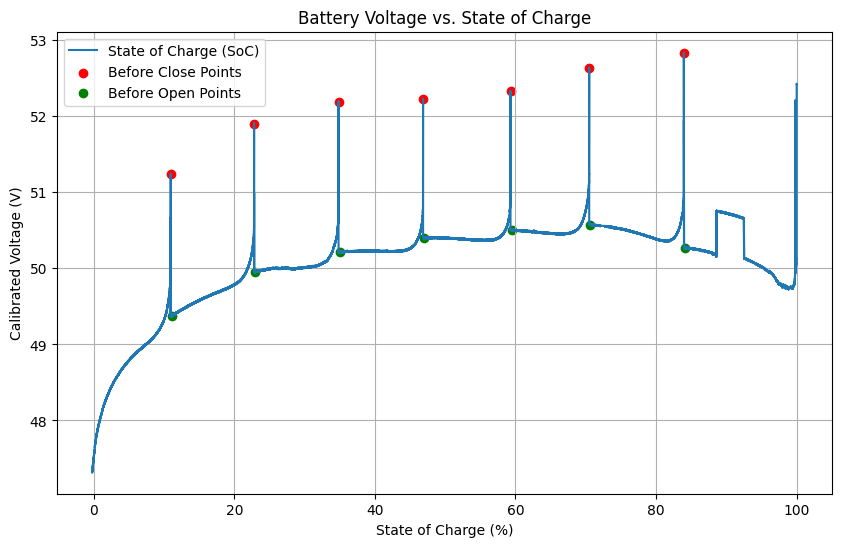

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(trimmed_df['SoC'], trimmed_df['Calibrated Voltage'], label='State of Charge (SoC)')
plt.scatter(before_close['SoC'], before_close['voltage'], color='red', label='Before Close Points')
plt.scatter(before_open['SoC'], before_open['voltage'], color='green', label='Before Open Points')
plt.xlabel('State of Charge (%)')
plt.ylabel('Calibrated Voltage (V)')
plt.title('Battery Voltage vs. State of Charge')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# As the final OCV at SoC = 0
last_point = trimmed_df.iloc[-1]

# the last sample is read under load, so it is below the OCV. 
# Add back the load current times the resistance seen at
# the lowest rest (loaded voltage just before that rest -> voltage at its end). Resistance rises further near empty, so this
# is still a low estimate of the OCV.
assert before_close['time'][-1] > before_open['time'][-1], "The lowest rest has no end point"
def mean_current(rows_df):
    return ((rows_df['Calibrated Current 1'] + rows_df['Calibrated Current 2']) / 2).mean()
open_index = before_open['index'][-1]
open_current = mean_current(trimmed_df.iloc[open_index - rows(0.2):open_index])
lowest_rest_resistance = (before_close['voltage'][-1] - before_open['voltage'][-1]) / open_current
end_current = mean_current(trimmed_df.iloc[-rows(1):])
ocv_at_end = last_point['Calibrated Voltage'] + end_current * lowest_rest_resistance
print(f"Lowest rest: {before_open['voltage'][-1]:.3f} V at {open_current:.1f} A -> {before_close['voltage'][-1]:.3f} V, resistance {lowest_rest_resistance:.4f} Ohm")
print(f"Last sample: {last_point['Calibrated Voltage']:.3f} V at {end_current:.1f} A -> OCV estimate {ocv_at_end:.3f} V")

if before_close['index'][-1] != len(trimmed_df) - 1:
    before_close['SoC'].append(last_point['SoC'])
    before_close['voltage'].append(ocv_at_end)
    before_close['index'].append(len(trimmed_df) - 1)

    print(f"Added last point to before_close: SoC={last_point['SoC']}, Voltage={ocv_at_end}, Index={len(trimmed_df) - 1}")

Lowest rest: 49.374 V at 24.7 A -> 51.237 V, resistance 0.0754 Ohm
Last sample: 47.314 V at 23.9 A -> OCV estimate 49.117 V
Added last point to before_close: SoC=-0.21882954112402514, Voltage=49.116649866009496, Index=9647167


In [ ]:
ocv_model = lambda soc, a, b, c, d, e: a + b * soc + c * soc**2 + d * np.log(soc) + e * np.log(100 - soc)
# log() needs 0 < SoC < 100 (the last point can be slightly negative after the sensor draw is subtracted).
# This model is only plotted for visual comparison
fit_soc = np.array(before_close['SoC'])
fit_voltage = np.array(before_close['voltage'])
in_range = (fit_soc > 0) & (fit_soc < 100)
try:
    parameters, covariance = curve_fit(ocv_model, fit_soc[in_range], fit_voltage[in_range], p0=[0.0, 0.01, -0.0001, 0.1, 0.1], maxfev=20000)
    a, b, c, d, e = parameters
    print(f"Fitted OCV model parameters: a={a:.5f}, b={b:.5f}, c={c:.5f}, d={d:.5f}, e={e:.5f}")
except RuntimeError as err:
    parameters = None
    print(f"OCV model fit failed: {err}")

Fitted OCV model parameters: a=41.72667, b=-0.11051, c=0.00093, d=2.45613, e=1.05180


In [13]:
def filter_df(soc, ocv, index_to_rm=[]):
    new_soc = []
    new_ocv = []
    for i in range(len(soc)):
        if i not in index_to_rm:
            new_soc.append(soc[i])
            new_ocv.append(ocv[i])
    return new_soc, new_ocv

Excluded unrested points (SoC, V): []
Extrapolated OCV at 100% SoC: 53.056 V (slope of top segment 0.0143 V/%)
OCV knots (SoC %, V): [(np.float64(-0.22), np.float64(49.117)), (np.float64(10.96), np.float64(51.237)), (np.float64(22.82), np.float64(51.903)), (np.float64(34.83), np.float64(52.188)), (np.float64(46.86), np.float64(52.221)), (np.float64(59.29), np.float64(52.325)), (np.float64(70.49), np.float64(52.635)), (np.float64(83.95), np.float64(52.827)), (np.float64(100.0), np.float64(53.056))]


C:\Users\Kor\AppData\Local\Temp\ipykernel_12496\1805665544.py:1: RuntimeWarning: divide by zero encountered in log
  ocv_model = lambda soc, a, b, c, d, e: a + b * soc + c * soc**2 + d * np.log(soc) + e * np.log(100 - soc)


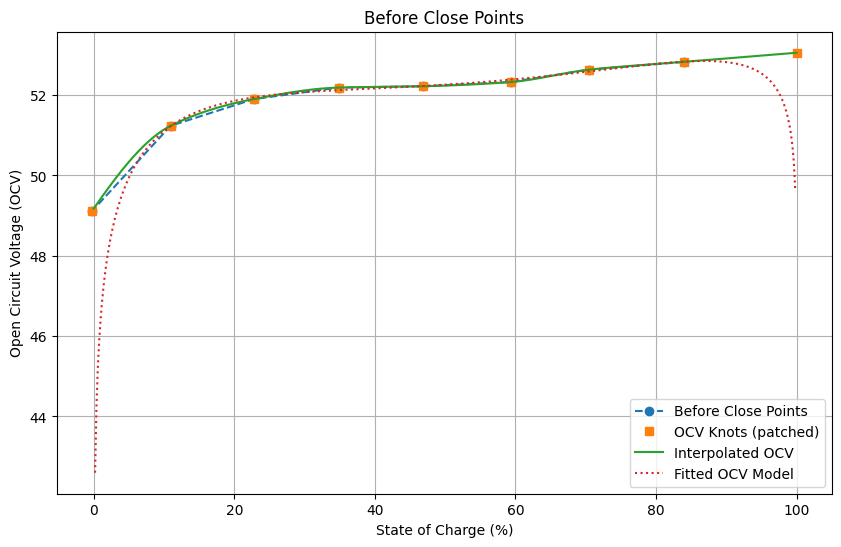

In [ ]:
#  - Ensure OCV always rise with SoC. A hump in the curve traps the EKF at the peak.
#  - Points above 99.5% SoC are excluded unless the settings say the first reading is a rested OCV.
#  - Pool adjacent violators so OCV never decreases as SoC rises.
#  - Extend to 100% SoC with the slope of the top segment instead of letting PCHIP extrapolate.
def pool_adjacent_violators(values):
    blocks = []  # [mean, count]
    for v in values:
        blocks.append([v, 1])
        while len(blocks) > 1 and blocks[-2][0] > blocks[-1][0]:
            v2, n2 = blocks.pop()
            v1, n1 = blocks.pop()
            blocks.append([(v1 * n1 + v2 * n2) / (n1 + n2), n1 + n2])
    return np.concatenate([[v] * n for v, n in blocks])

order = np.argsort(before_close['SoC'])
soc = np.array(before_close['SoC'])[order]
ocv = np.array(before_close['voltage'])[order]
unrested = (soc >= 99.5) & (not SETTINGS["start_is_rested_ocv"])
print(f"Excluded unrested points (SoC, V): {list(zip(soc[unrested].round(2), ocv[unrested].round(3)))}")
soc, ocv = soc[~unrested], ocv[~unrested]
pooled = pool_adjacent_violators(ocv)
for s, before, after in zip(soc, ocv, pooled):
    if abs(before - after) > 1e-9:
        print(f"Pooled point at SoC {s:.2f}%: {before:.3f} V -> {after:.3f} V")
ocv = pooled
if soc[-1] < 100:
    top_slope = max((ocv[-1] - ocv[-2]) / (soc[-1] - soc[-2]), 0.0)
    ocv = np.append(ocv, ocv[-1] + top_slope * (100 - soc[-1]))
    soc = np.append(soc, 100.0)
    print(f"Extrapolated OCV at 100% SoC: {ocv[-1]:.3f} V (slope of top segment {top_slope:.4f} V/%)")
print("OCV knots (SoC %, V):", list(zip(soc.round(2), ocv.round(3))))

soc_smooth = np.linspace(0, 100, 500)
piecewise_cubic_interp = PchipInterpolator(soc, ocv, extrapolate=False)
piecewise_cubic_spline_ocv_smooth = piecewise_cubic_interp(np.clip(soc_smooth, soc[0], soc[-1]))

plt.figure(figsize=(10, 6))
plt.plot(before_close['SoC'], before_close['voltage'], label='Before Close Points', linestyle='--', marker='o')
plt.plot(soc, ocv, label='OCV Knots (patched)', linestyle='', marker='s')
plt.plot(soc_smooth, piecewise_cubic_spline_ocv_smooth, label='Interpolated OCV', linestyle='-')
if parameters is not None:
    plt.plot(soc_smooth, ocv_model(soc_smooth, *parameters), label='Fitted OCV Model', linestyle=':')

plt.xlabel('State of Charge (%)')
plt.ylabel('Open Circuit Voltage (OCV)')
plt.title('Before Close Points')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Piecewise Function

print("Function: f(x) = c0*(x-x_i)^3 + c1*(x-x_i)^2 + c2*(x-x_i) + c3 for x in [x_i, x_{i+1}]")
knots = piecewise_cubic_interp.x
coef = piecewise_cubic_interp.c
intervals = len(coef[0])
print(f"Total number of intervals: {intervals}")
for i in range(intervals):
    print(f"Interval {i}:\tx in [{knots[i]}, {knots[i+1]}]")
    print(f"\t\tCoefficients: c0={coef[0][i]}, c1={coef[1][i]}, c2={coef[2][i]}, c3={coef[3][i]}")

Function: f(x) = c0*(x-x_i)^3 + c1*(x-x_i)^2 + c2*(x-x_i) + c3 for x in [x_i, x_{i+1}]
Total number of intervals: 8
Interval 0:	x in [-0.21882954112402514, 10.957110741685339]
		Coefficients: c0=-0.0003029153323187773, c1=-0.0024134146745817433, c2=0.2545396402503862, c3=49.116649866009496
Interval 1:	x in [10.957110741685339, 22.82274741499905]
		Coefficients: c0=5.850156711894575e-05, c1=-0.003304349063554231, c2=0.08709141723057542, c3=51.23709275349051
Interval 2:	x in [22.82274741499905, 34.83046742252191]
		Coefficients: c0=-6.347979604246233e-05, c1=-4.161341492510591e-05, c2=0.0333848983482713, c3=51.90299041428243
Interval 3:	x in [34.83046742252191, 46.85740460254018]
		Coefficients: c0=2.4608354703219994e-05, c1=-0.0004771228157608147, c2=0.004926965993851699, c3=52.187961950103
Interval 4:	x in [46.85740460254018, 59.29410959886293]
		Coefficients: c0=2.2136970259058227e-06, c1=0.0003153429196077169, c2=0.004128903866355868, c3=52.22101401693752
Interval 5:	x in [59.2941095

In [16]:
knots = piecewise_cubic_interp.x
coef = piecewise_cubic_interp.c
intervals = len(coef[0])
print(f"Total number of intervals: {intervals}")
for i in range(intervals):
    print(f"Interval {i}: f(x) = {coef[0][i]} * (x-{knots[i]})**3 + {coef[1][i]} * (x-{knots[i]})**2 + {coef[2][i]} * (x-{knots[i]}) + {coef[3][i]} \n\tfor x in [{knots[i]}, {knots[i+1]}]")
    


Total number of intervals: 8
Interval 0: f(x) = -0.0003029153323187773 * (x--0.21882954112402514)**3 + -0.0024134146745817433 * (x--0.21882954112402514)**2 + 0.2545396402503862 * (x--0.21882954112402514) + 49.116649866009496 
	for x in [-0.21882954112402514, 10.957110741685339]
Interval 1: f(x) = 5.850156711894575e-05 * (x-10.957110741685339)**3 + -0.003304349063554231 * (x-10.957110741685339)**2 + 0.08709141723057542 * (x-10.957110741685339) + 51.23709275349051 
	for x in [10.957110741685339, 22.82274741499905]
Interval 2: f(x) = -6.347979604246233e-05 * (x-22.82274741499905)**3 + -4.161341492510591e-05 * (x-22.82274741499905)**2 + 0.0333848983482713 * (x-22.82274741499905) + 51.90299041428243 
	for x in [22.82274741499905, 34.83046742252191]
Interval 3: f(x) = 2.4608354703219994e-05 * (x-34.83046742252191)**3 + -0.0004771228157608147 * (x-34.83046742252191)**2 + 0.004926965993851699 * (x-34.83046742252191) + 52.187961950103 
	for x in [34.83046742252191, 46.85740460254018]
Interval 4

In [17]:
# 2 options: Reverse each interval function to get SoC from OCV or a dictionary of OCV to SoC values for each point ~1000 interval.

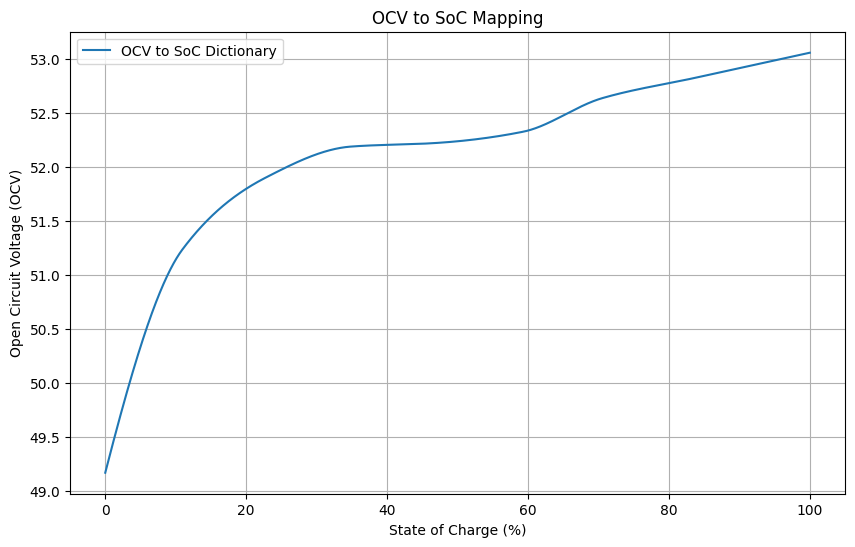

In [ ]:
# Option 2: Faster O(1), but takes ~3000kb of data for 3 dp precision. 
# Not suitable for microcontroller but can be used for RPi

factor = 3 # Number of dp
array_interval = factor + 2 # Additional 2 for 0 - 100% SoC
ocv_soc_dict = {}
ocv_intervals = np.linspace(0, 100, 10**array_interval + 1)
for ocv_value in ocv_intervals:
    soc_value = piecewise_cubic_interp(np.clip(ocv_value, piecewise_cubic_interp.x[0], piecewise_cubic_interp.x[-1]))  # fix: remove  extrapolation
    ocv_soc_dict[round(ocv_value, factor+2)] = soc_value.item()

output_df = pd.DataFrame({
    "SoC": list(ocv_soc_dict.keys()),
    "OCV": list(ocv_soc_dict.values())
})

plt.figure(figsize=(10, 6))
plt.plot(output_df['SoC'], output_df['OCV'], label='OCV to SoC Dictionary', linestyle='-')
plt.xlabel('State of Charge (%)')
plt.ylabel('Open Circuit Voltage (OCV)')
plt.title('OCV to SoC Mapping')
plt.legend()
plt.grid(True)
plt.show()

In [19]:
output_df.to_csv(ocv_soc_dict_file_name, index=False)
print(f"Saved OCV to SoC dictionary with {len(ocv_soc_dict)} entries to {ocv_soc_dict_file_name}")
print(f"To use, get the ceiling of voltage reading to {factor} decimal places and look up corresponding SoC value in the dictionary.")

Saved OCV to SoC dictionary with 100001 entries to C:\Users\Kor\Documents\GitHub\solar_proa_network_server\final_report\Calibration Code\LiFePO4 Patch Output\ocv_soc_dict.csv
To use, get the ceiling of voltage reading to 3 decimal places and look up corresponding SoC value in the dictionary.


In [20]:
compiled_df.to_csv(output_file_name, index=False)